# 01 — Data, features, corruption

Part 1 of the pipeline: load the raw UCI HAR inertial windows, extract 63 hand-crafted features (9 channels × 7 features), and inspect the three controlled corruptions (`gaussian`, `missing`, `ood`) that Parts 2–3 sweep over.

In [1]:
import os, sys
os.chdir('..'); sys.path.append('.')

In [2]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.config import ACTIVITIES, DATA_DIR, SEED
from src.data.load import load_raw, CHANNELS
from src.data.features import extract_features, feature_names, FEATURES, FS
from src.data.corrupt import corrupt, mean_impute

sns.set_theme(style='whitegrid', context='notebook')
pd.set_option('display.precision', 3)

## 1. Raw data

In [3]:
X_raw, y, subj = load_raw(DATA_DIR)
n, T, C = X_raw.shape
print(f'windows: {n:,}   time steps: {T} ({T / FS:.2f} s @ {FS} Hz)   channels: {C}')
print(f'subjects: {len(np.unique(subj))}   dtype: {X_raw.dtype}')
print('channels:', ', '.join(CHANNELS))

counts = np.bincount(y, minlength=len(ACTIVITIES))
balance = pd.DataFrame({'activity': ACTIVITIES, 'count': counts, 'share_%': 100 * counts / n})
balance.index.name = 'label'
balance

windows: 10,299   time steps: 128 (2.56 s @ 50 Hz)   channels: 9
subjects: 30   dtype: float32
channels: body_acc_x, body_acc_y, body_acc_z, body_gyro_x, body_gyro_y, body_gyro_z, total_acc_x, total_acc_y, total_acc_z


,activity,count,share_%
label,,,
0,WALKING,1722,16.720
1,UPSTAIRS,1544,14.992
2,DOWNSTAIRS,1406,13.652
3,SITTING,1777,17.254
4,STANDING,1906,18.507
5,LAYING,1944,18.876


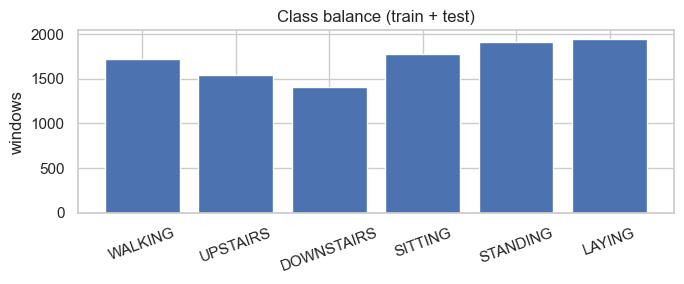

In [4]:
fig, ax = plt.subplots(figsize=(7, 3))
ax.bar(ACTIVITIES, counts, color='#4c72b0')
ax.set_ylabel('windows'); ax.set_title('Class balance (train + test)')
plt.xticks(rotation=20); plt.tight_layout(); plt.show()

## 2. Raw waveforms: dynamic vs static

One representative window per activity. `WALKING` shows periodic body acceleration and rotation; `SITTING` / `LAYING` are near-flat in `body_acc` / `body_gyro`, and differ mainly in which axis carries gravity in `total_acc`.

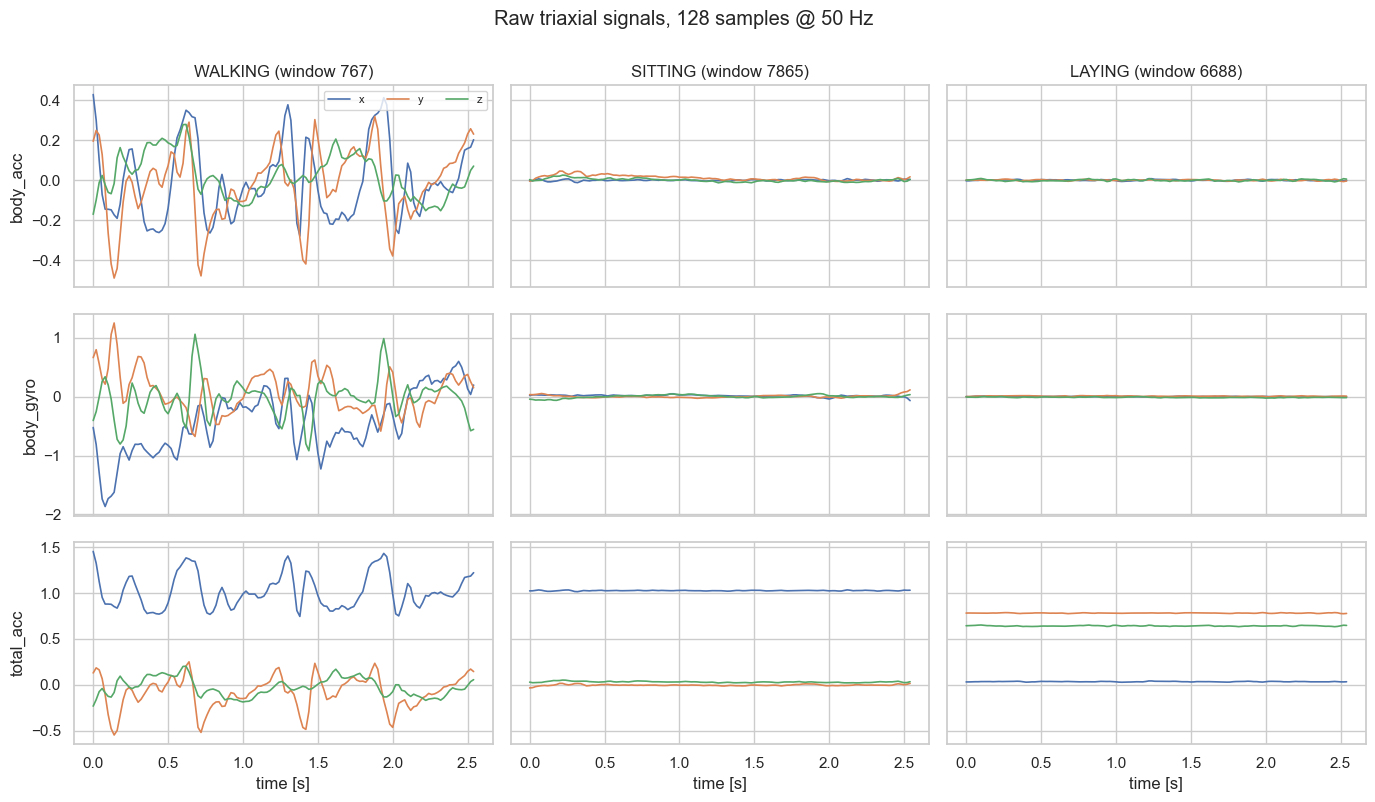

In [5]:
show = ['WALKING', 'SITTING', 'LAYING']
groups = [('body_acc', slice(0, 3)), ('body_gyro', slice(3, 6)), ('total_acc', slice(6, 9))]
rng = np.random.default_rng(SEED)
t = np.arange(T) / FS

fig, axes = plt.subplots(len(groups), len(show), figsize=(14, 8), sharex=True, sharey='row')
for j, act in enumerate(show):
    i = rng.choice(np.flatnonzero(y == ACTIVITIES.index(act)))
    for r, (g, sl) in enumerate(groups):
        ax = axes[r, j]
        for k, axis in enumerate('xyz'):
            ax.plot(t, X_raw[i, :, sl][:, k], lw=1.2, label=axis)
        if r == 0: ax.set_title(f'{act} (window {i})')
        if j == 0: ax.set_ylabel(g)
        if r == len(groups) - 1: ax.set_xlabel('time [s]')
axes[0, 0].legend(loc='upper right', ncol=3, fontsize=8)
plt.suptitle('Raw triaxial signals, 128 samples @ 50 Hz', y=1.0)
plt.tight_layout(); plt.show()

## 3. Feature extraction

Per channel: `mean`, `std`, `min`, `max`, `energy` (mean squared amplitude), `entropy` (Shannon entropy of the normalised non-DC power spectrum) and `dom_freq` (dominant non-DC FFT frequency, Hz). Columns are channel-major: `body_acc_x_mean, body_acc_x_std, …`.

In [6]:
t0 = time.perf_counter()
X = extract_features(X_raw)
elapsed = time.perf_counter() - t0
names = feature_names()
print(f'X: {X.shape}, {X.dtype}, {elapsed:.3f} s, NaN={np.isnan(X).sum()}, Inf={np.isinf(X).sum()}')
assert X.shape == (n, 63) and len(names) == 63 and np.isfinite(X).all()

df = pd.DataFrame(X, columns=names)
df.describe().T

X: (10299, 63), float64, 0.236 s, NaN=0, Inf=0


,count,mean,std,min,25%,50%,75%,max
body_acc_x_mean,10299.0,-6.653e-04,0.014,-2.633e-01,-3.081e-03,-8.282e-05,0.002,0.149
body_acc_x_std,10299.0,1.283e-01,0.142,1.413e-03,3.885e-03,1.985e-02,0.244,0.649
body_acc_x_min,10299.0,-2.214e-01,0.236,-1.232e+00,-4.287e-01,-4.983e-02,-0.010,0.093
body_acc_x_max,10299.0,3.226e-01,0.359,-3.268e-02,1.010e-02,5.072e-02,0.624,1.300
body_acc_x_energy,10299.0,3.682e-02,0.052,2.120e-06,1.700e-05,4.798e-04,0.060,0.422
...,...,...,...,...,...,...,...,...
total_acc_z_min,10299.0,-1.025e-01,0.473,-1.640e+00,-3.993e-01,-1.085e-01,0.168,0.966
total_acc_z_max,10299.0,2.406e-01,0.295,-9.780e-01,4.773e-02,2.112e-01,0.397,1.281
total_acc_z_energy,10299.0,1.257e-01,0.206,1.369e-05,1.501e-02,3.656e-02,0.118,0.977
total_acc_z_entropy,10299.0,2.508e+00,0.526,4.287e-01,2.195e+00,2.591e+00,2.916,3.556


In [7]:
# Per feature type, averaged across the 9 channels and split by activity
by_type = pd.DataFrame(X.reshape(n, C, len(FEATURES)).mean(axis=1), columns=FEATURES)
by_type['activity'] = np.array(ACTIVITIES)[y]
by_type.groupby('activity')[FEATURES].mean().loc[ACTIVITIES]

,mean,std,min,max,energy,entropy,dom_freq
activity,,,,,,,
WALKING,0.084,0.259,-0.526,0.690,0.212,2.372,1.971
UPSTAIRS,0.060,0.274,-0.534,0.686,0.234,2.001,1.254
DOWNSTAIRS,0.083,0.312,-0.672,0.827,0.262,2.435,1.980
SITTING,0.136,0.014,0.101,0.169,0.118,2.522,1.441
STANDING,0.091,0.018,0.045,0.137,0.120,2.485,1.432
LAYING,0.141,0.016,0.101,0.181,0.115,2.421,1.475


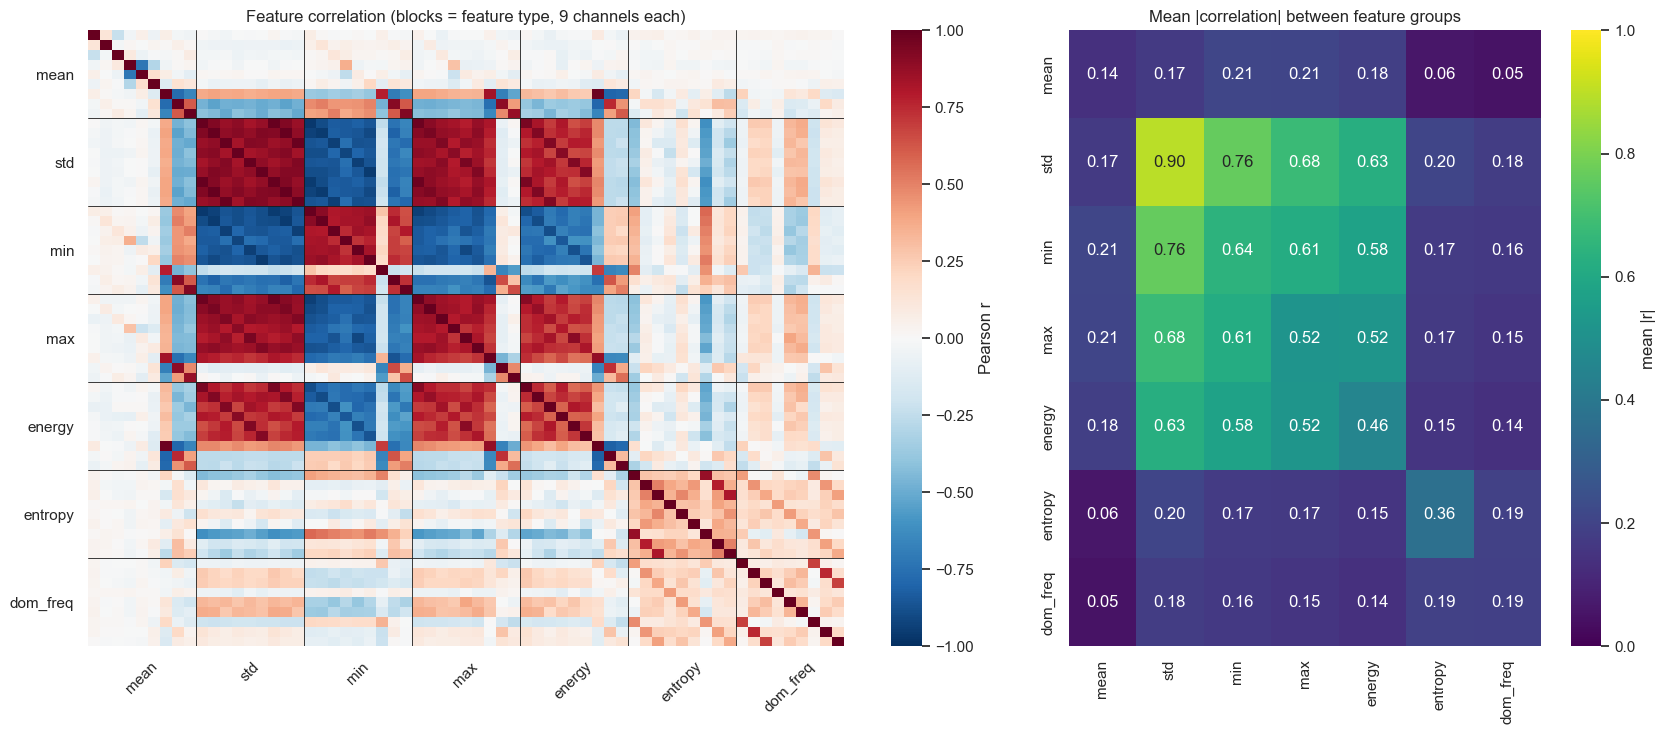

In [8]:
# Full 63x63 correlation, columns reordered feature-type-major so blocks = feature groups
order = [f'{ch}_{f}' for f in FEATURES for ch in CHANNELS]
corr = df[order].corr()

fig, axes = plt.subplots(1, 2, figsize=(17, 7.5), gridspec_kw={'width_ratios': [1.6, 1]})
sns.heatmap(corr, cmap='RdBu_r', vmin=-1, vmax=1, ax=axes[0], xticklabels=False, yticklabels=False,
            cbar_kws={'label': 'Pearson r'})
ticks = np.arange(len(FEATURES)) * C + C / 2
for ax_ in (axes[0].set_xticks, axes[0].set_yticks): ax_(ticks)
axes[0].set_xticklabels(FEATURES, rotation=45); axes[0].set_yticklabels(FEATURES, rotation=0)
for b in range(1, len(FEATURES)):
    axes[0].axhline(b * C, color='k', lw=0.6); axes[0].axvline(b * C, color='k', lw=0.6)
axes[0].set_title('Feature correlation (blocks = feature type, 9 channels each)')

# Group-level summary: mean |r| between feature types (diagonal excludes self-correlation)
A = np.abs(corr.values)
G = np.zeros((len(FEATURES), len(FEATURES)))
for a in range(len(FEATURES)):
    for b in range(len(FEATURES)):
        blk = A[a * C:(a + 1) * C, b * C:(b + 1) * C]
        G[a, b] = blk[~np.eye(C, dtype=bool)].mean() if a == b else blk.mean()
sns.heatmap(pd.DataFrame(G, FEATURES, FEATURES), annot=True, fmt='.2f', cmap='viridis', vmin=0, vmax=1,
            ax=axes[1], cbar_kws={'label': 'mean |r|'})
axes[1].set_title('Mean |correlation| between feature groups')
plt.tight_layout(); plt.show()

## 4. Controlled corruption

Each corruption is shown at 0 %, 25 % and 50 % on three key features. `missing` is shown after `mean_impute` (here the whole matrix stands in for the train fold; in the CV sweep the means come from the training fold only).

In [9]:
levels = [0.0, 0.25, 0.5]
kinds = ['gaussian', 'missing', 'ood']
key = ['total_acc_x_mean', 'body_acc_x_std', 'body_gyro_y_entropy']
cols = [names.index(k) for k in key]

Xc = {}
for kind in kinds:
    for lv in levels:
        t0 = time.perf_counter()
        Z = corrupt(X, X_raw, kind, lv, seed=SEED)
        nan_frac = np.isnan(Z).mean()
        if kind == 'missing':
            Z, _ = mean_impute(Z, Z)
        Xc[kind, lv] = Z
        changed = (~np.isclose(Z, X)).any(axis=1).mean()
        print(f'{kind:8s} level={lv:.2f}  NaN before impute={nan_frac:6.1%}  rows changed={changed:6.1%}  '
              f'NaN after={np.isnan(Z).sum()}  ({time.perf_counter() - t0:.2f}s)')
assert all(np.isfinite(Z).all() for Z in Xc.values())
assert np.array_equal(X, extract_features(X_raw)), 'X was mutated'

gaussian level=0.00  NaN before impute=  0.0%  rows changed=  0.0%  NaN after=0  (0.00s)
gaussian level=0.25  NaN before impute=  0.0%  rows changed=100.0%  NaN after=0  (0.01s)
gaussian level=0.50  NaN before impute=  0.0%  rows changed=100.0%  NaN after=0  (0.01s)
missing  level=0.00  NaN before impute=  0.0%  rows changed=  0.0%  NaN after=0  (0.01s)
missing  level=0.25  NaN before impute= 25.0%  rows changed=100.0%  NaN after=0  (0.02s)
missing  level=0.50  NaN before impute= 50.0%  rows changed=100.0%  NaN after=0  (0.02s)
ood      level=0.00  NaN before impute=  0.0%  rows changed=  0.0%  NaN after=0  (0.00s)
ood      level=0.25  NaN before impute=  0.0%  rows changed= 25.0%  NaN after=0  (0.09s)


ood      level=0.50  NaN before impute=  0.0%  rows changed= 50.0%  NaN after=0  (0.17s)


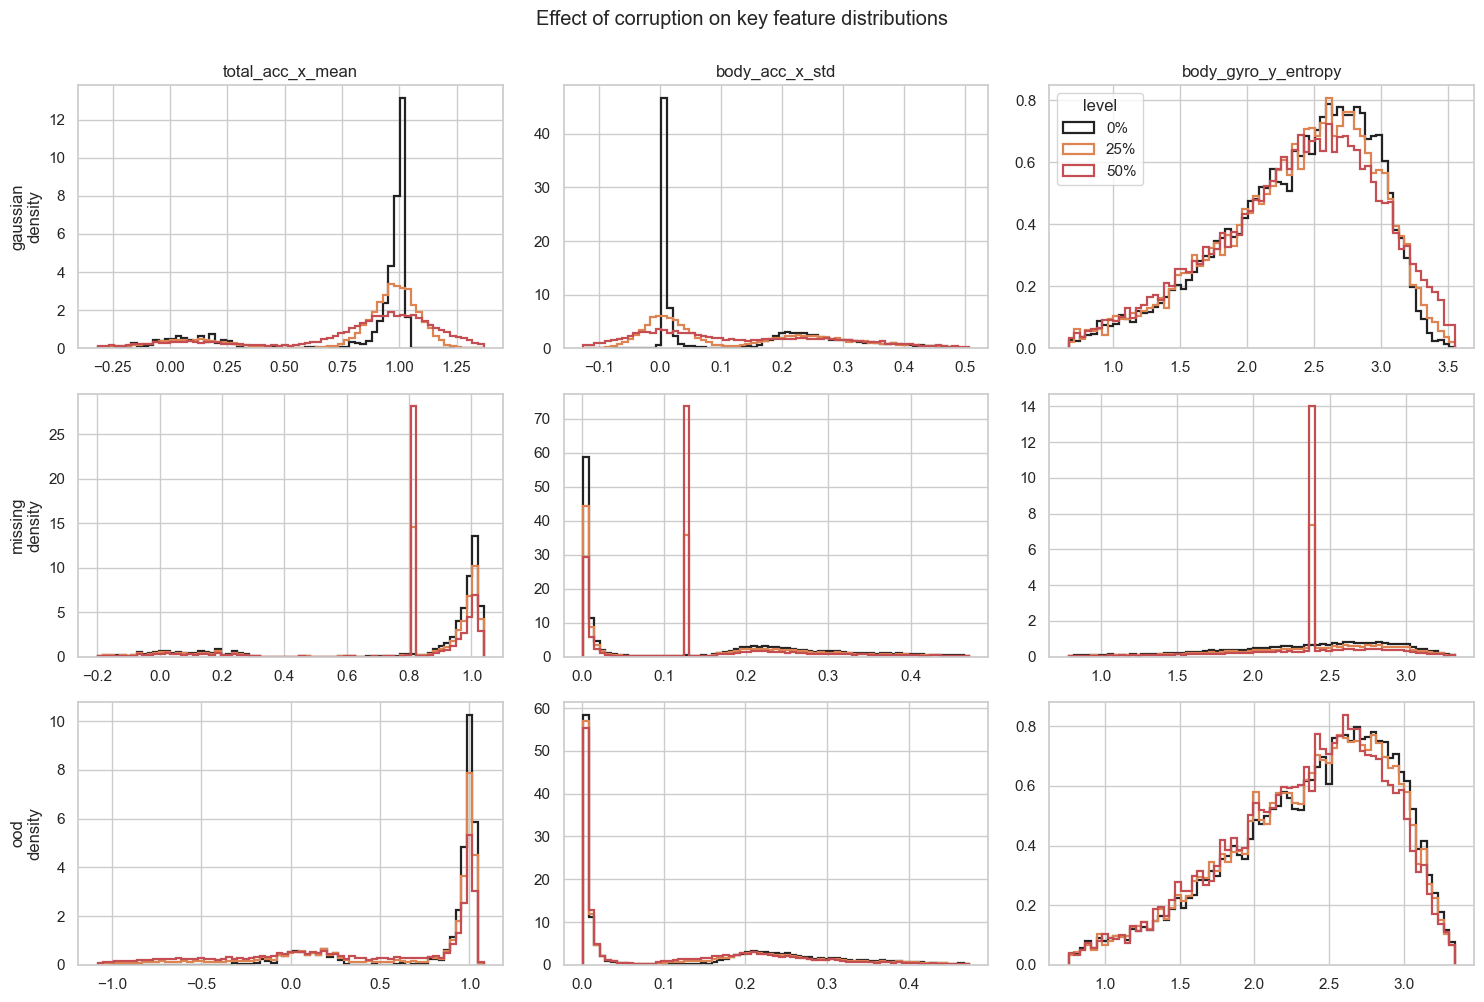

In [10]:
palette = dict(zip(levels, ['#222222', '#dd8452', '#c44e52']))
fig, axes = plt.subplots(len(kinds), len(key), figsize=(15, 10))
for r, kind in enumerate(kinds):
    for c, (k, j) in enumerate(zip(key, cols)):
        ax = axes[r, c]
        lo, hi = np.percentile(np.concatenate([Xc[kind, lv][:, j] for lv in levels]), [0.5, 99.5])
        bins = np.linspace(lo, hi, 70)
        for lv in levels:
            ax.hist(Xc[kind, lv][:, j], bins=bins, histtype='step', lw=1.6, density=True,
                    color=palette[lv], label=f'{lv:.0%}')
        if r == 0: ax.set_title(k)
        if c == 0: ax.set_ylabel(f'{kind}\ndensity')
axes[0, -1].legend(title='level')
plt.suptitle('Effect of corruption on key feature distributions', y=1.0)
plt.tight_layout(); plt.show()

**Reading the plots.** Gaussian noise widens every distribution in proportion to its spread. Missing values + mean imputation collapse the imputed fraction onto a spike at the column mean, shrinking variance. OOD rotation/gain moves gravity between axes, so orientation-dependent features such as `total_acc_x_mean` shift far outside the clean range — a genuine covariate shift rather than additive noise.